In [1]:

# Phase 08 — Visualizations and Decision Memo
# Step 08.03 — Import required libraries

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ab_data_provisional_user_level.csv"
)

FIGURES_DIR = PROJECT_ROOT / "figures"

print("Phase 08 libraries imported successfully.")
print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.is_file())
print("Figures folder exists:", FIGURES_DIR.is_dir())


Phase 08 libraries imported successfully.
Project root: C:\Users\kunal\OneDrive\Desktop\ab-test-experiment-analysis
Dataset exists: True
Figures folder exists: True


In [2]:

# Step 08.04 — Load and validate provisional dataset

df = pd.read_csv(DATA_PATH)

required_columns = {
    "user_id",
    "group",
    "landing_page",
    "converted"
}

missing_columns = required_columns - set(df.columns)

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

print("========== DATASET VALIDATION ==========")
print(f"Total rows: {len(df):,}")
print(f"Unique users: {df['user_id'].nunique():,}")

print("\n========== EXPERIMENT GROUPS ==========")
print(df["group"].value_counts())

print("\n========== CONVERSION COUNTS ==========")
print(df.groupby("group")["converted"].sum())

# Verify against previously approved results
assert len(df) == 290_584
assert df["user_id"].nunique() == 290_584

assert df["group"].value_counts()["control"] == 145_294
assert df["group"].value_counts()["treatment"] == 145_290

assert df.groupby("group")["converted"].sum()["control"] == 17_496
assert df.groupby("group")["converted"].sum()["treatment"] == 17_265

print("\nAll primary dataset checks passed.")


========== DATASET VALIDATION ==========
Total rows: 290,584
Unique users: 290,584

========== EXPERIMENT GROUPS ==========
group
control      145294
treatment    145290
Name: count, dtype: int64

========== CONVERSION COUNTS ==========
group
control      17496
treatment    17265
Name: converted, dtype: int64

All primary dataset checks passed.


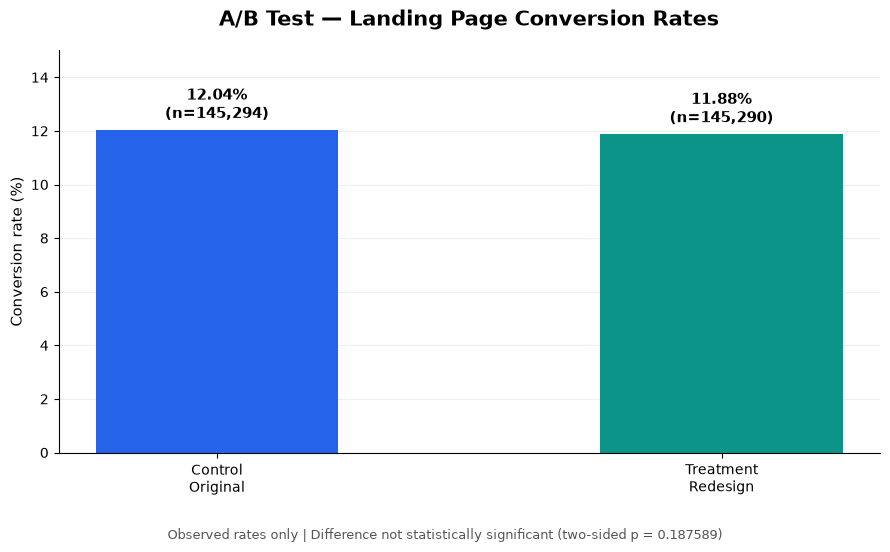

Chart 1 saved successfully.
File: C:\Users\kunal\OneDrive\Desktop\ab-test-experiment-analysis\figures\08_conversion_rate_comparison.png
File exists: True


In [3]:

# Step 08.05 — Chart 1: Conversion Rate Comparison

# Calculate conversion rates directly from verified data
summary = (
    df.groupby("group")["converted"]
    .agg(["count", "sum", "mean"])
    .reindex(["control", "treatment"])
)

assert summary["count"].tolist() == [145294, 145290]
assert summary["sum"].tolist() == [17496, 17265]

rates = summary["mean"] * 100

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    ["Control\nOriginal", "Treatment\nRedesign"],
    rates,
    color=["#2563EB", "#0D9488"],
    width=0.48
)

ax.set_title(
    "A/B Test — Landing Page Conversion Rates",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Conversion rate (%)", fontsize=11)
ax.set_ylim(0, 15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bar, rate, count in zip(
    bars,
    rates,
    summary["count"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{rate:.2f}%\n(n={count:,})",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

fig.text(
    0.5, 0.01,
    "Observed rates only | Difference not statistically significant "
    "(two-sided p = 0.187589)",
    ha="center",
    fontsize=9,
    color="#555555"
)


plt.tight_layout(rect=[0, 0.06, 1, 1])

# Save Chart 1 as a high-resolution PNG
chart_1_path = (
    FIGURES_DIR / "08_conversion_rate_comparison.png"
)

fig.savefig(
    chart_1_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart 1 saved successfully.")
print("File:", chart_1_path)
print("File exists:", chart_1_path.is_file())



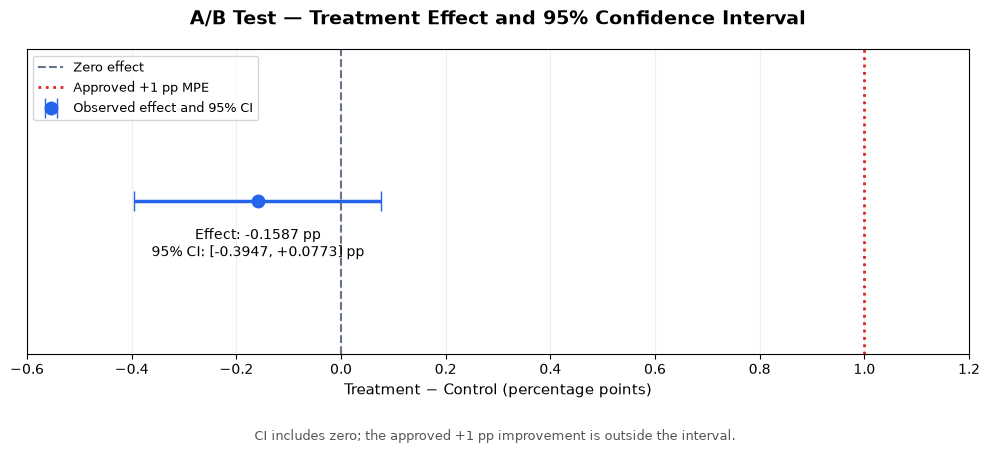

Chart 2 saved successfully.
File: C:\Users\kunal\OneDrive\Desktop\ab-test-experiment-analysis\figures\08_treatment_effect_ci.png
File exists: True


In [4]:

# Step 08.07 — Chart 2: Treatment Effect and 95% CI

effect_pp = -0.158661
ci_lower_pp = -0.3947
ci_upper_pp = 0.0773
mpe_pp = 1.0

# Verify consistency with the dataset
calculated_effect_pp = (
    summary.loc["treatment", "mean"]
    - summary.loc["control", "mean"]
) * 100

assert np.isclose(
    calculated_effect_pp,
    effect_pp,
    atol=0.00001
)

fig2, ax2 = plt.subplots(figsize=(10, 4.5))

ax2.errorbar(
    effect_pp,
    0,
    xerr=[
        [effect_pp - ci_lower_pp],
        [ci_upper_pp - effect_pp]
    ],
    fmt="o",
    color="#2563EB",
    ecolor="#2563EB",
    markersize=9,
    capsize=7,
    linewidth=2.5,
    label="Observed effect and 95% CI"
)

ax2.axvline(
    0,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Zero effect"
)

ax2.axvline(
    mpe_pp,
    color="#DC2626",
    linestyle=":",
    linewidth=2,
    label="Approved +1 pp MPE"
)

ax2.set_xlim(-0.6, 1.2)
ax2.set_ylim(-0.5, 0.5)
ax2.set_yticks([])

ax2.set_xlabel(
    "Treatment − Control (percentage points)",
    fontsize=11
)

ax2.set_title(
    "A/B Test — Treatment Effect and 95% Confidence Interval",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax2.grid(axis="x", alpha=0.2)
ax2.set_axisbelow(True)

ax2.legend(loc="upper left", fontsize=9)

ax2.text(
    effect_pp,
    -0.18,
    f"Effect: {effect_pp:+.4f} pp\n"
    f"95% CI: [{ci_lower_pp:+.4f}, {ci_upper_pp:+.4f}] pp",
    ha="center",
    fontsize=10
)

fig2.text(
    0.5,
    0.01,
    "CI includes zero; the approved +1 pp improvement "
    "is outside the interval.",
    ha="center",
    fontsize=9,
    color="#555555"
)


plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save Chart 2 as a high-resolution PNG
chart_2_path = (
    FIGURES_DIR / "08_treatment_effect_ci.png"
)

fig2.savefig(
    chart_2_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart 2 saved successfully.")
print("File:", chart_2_path)
print("File exists:", chart_2_path.is_file())



In [5]:

# Step 08.10 — Prepare verified Phase 07 robustness results
# Values reproduced from the approved Phase 07 report.
# These are rounded, previously verified results.

robustness_plot_data = pd.DataFrame({
    "Analysis": [
        "Primary",
        "Exclude page mismatches",
        "Exclude cross-group users",
        "Exclude repeated users"
    ],
    "Users": [
        290584,
        288635,
        288689,
        286690
    ],
    "Effect_pp": [
        -0.1587,
        -0.1695,
        -0.1633,
        -0.1447
    ],
    "CI_lower_pp": [
        -0.3947,
        -0.4062,
        -0.4000,
        -0.3821
    ],
    "CI_upper_pp": [
        0.0773,
        0.0672,
        0.0735,
        0.0927
    ]
})

# Basic validation
assert len(robustness_plot_data) == 4

assert (
    robustness_plot_data["CI_lower_pp"]
    <= robustness_plot_data["Effect_pp"]
).all()

assert (
    robustness_plot_data["Effect_pp"]
    <= robustness_plot_data["CI_upper_pp"]
).all()

print("Verified Phase 07 robustness results loaded.")
print(robustness_plot_data.to_string(index=False))


Verified Phase 07 robustness results loaded.
                 Analysis  Users  Effect_pp  CI_lower_pp  CI_upper_pp
                  Primary 290584    -0.1587      -0.3947       0.0773
  Exclude page mismatches 288635    -0.1695      -0.4062       0.0672
Exclude cross-group users 288689    -0.1633      -0.4000       0.0735
   Exclude repeated users 286690    -0.1447      -0.3821       0.0927


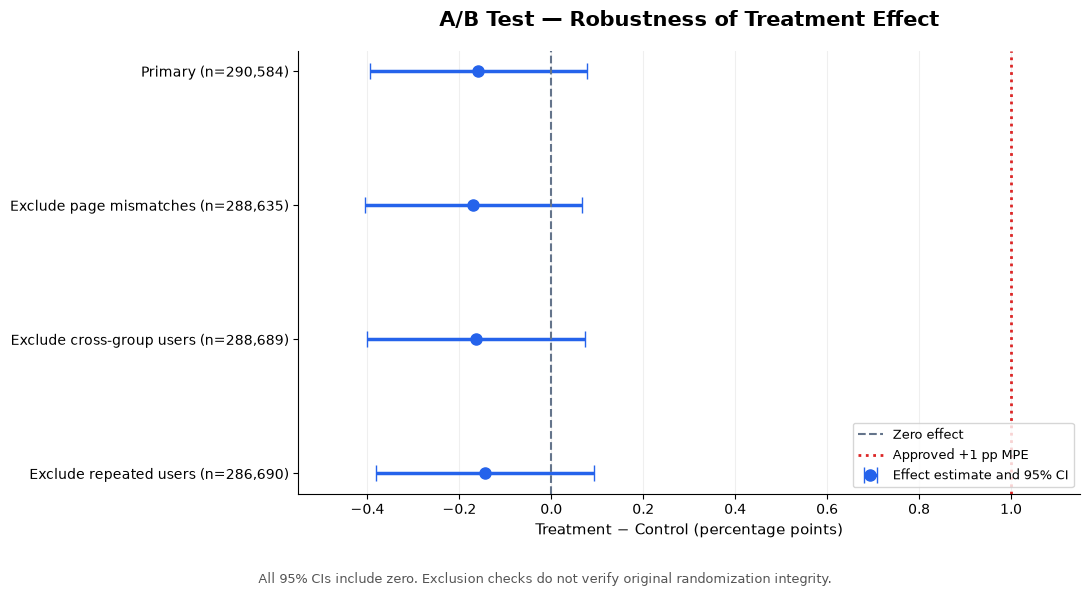

Chart 3 saved successfully.
File: C:\Users\kunal\OneDrive\Desktop\ab-test-experiment-analysis\figures\08_robustness_comparison.png
File exists: True


In [6]:

# Step 08.11 — Chart 3: Robustness Comparison

plot_data = robustness_plot_data.copy()

y_positions = np.arange(len(plot_data))
effects = plot_data["Effect_pp"].to_numpy()

lower_errors = (
    effects - plot_data["CI_lower_pp"].to_numpy()
)

upper_errors = (
    plot_data["CI_upper_pp"].to_numpy() - effects
)

fig3, ax3 = plt.subplots(figsize=(11, 6))

# Plot estimates and 95% confidence intervals
ax3.errorbar(
    effects,
    y_positions,
    xerr=[lower_errors, upper_errors],
    fmt="o",
    color="#2563EB",
    ecolor="#2563EB",
    markersize=8,
    capsize=6,
    linewidth=2.5,
    label="Effect estimate and 95% CI"
)

# Zero-effect reference
ax3.axvline(
    0,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Zero effect"
)

# Approved practical improvement threshold
ax3.axvline(
    1.0,
    color="#DC2626",
    linestyle=":",
    linewidth=2,
    label="Approved +1 pp MPE"
)

ax3.set_yticks(y_positions)
ax3.set_yticklabels(
    [
        f"{name} (n={users:,})"
        for name, users in zip(
            plot_data["Analysis"],
            plot_data["Users"]
        )
    ],
    fontsize=10
)

ax3.invert_yaxis()

ax3.set_xlim(-0.55, 1.15)

ax3.set_xlabel(
    "Treatment − Control (percentage points)",
    fontsize=11
)

ax3.set_title(
    "A/B Test — Robustness of Treatment Effect",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax3.grid(axis="x", alpha=0.2)
ax3.set_axisbelow(True)

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

ax3.legend(
    loc="lower right",
    fontsize=9
)

fig3.text(
    0.5,
    0.02,
    "All 95% CIs include zero. Exclusion checks do not "
    "verify original randomization integrity.",
    ha="center",
    fontsize=9,
    color="#555555"
)


plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save Chart 3 as a high-resolution PNG
chart_3_path = (
    FIGURES_DIR / "08_robustness_comparison.png"
)

fig3.savefig(
    chart_3_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart 3 saved successfully.")
print("File:", chart_3_path)
print("File exists:", chart_3_path.is_file())

